In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('mail_data.csv')

In [ ]:
df.head()

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
df.shape

(5572, 2)

In [ ]:
df.columns

Index(['Category', 'Message'], dtype='object')

In [ ]:
X = df['Message']
y = df['Category']

print(X.head())
print(y.head())

0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: Message, dtype: object
0     ham
1     ham
2    spam
3     ham
4     ham
Name: Category, dtype: object


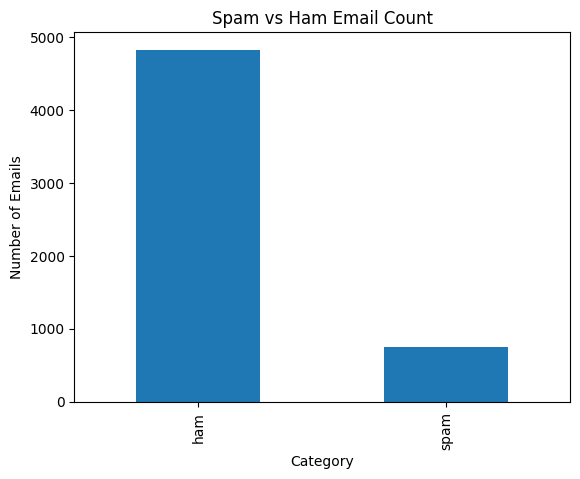

In [ ]:
import matplotlib.pyplot as plt

df['Category'].value_counts().plot(kind='bar')

plt.title('Spam vs Ham Email Count')
plt.xlabel('Category')
plt.ylabel('Number of Emails')
plt.show()

In [ ]:
df.isnull().sum()

,0
Category,0
Message,0


In [ ]:
df.duplicated().sum()

np.int64(415)

In [ ]:
df.drop_duplicates().sum()

,0
Category,hamhamspamhamhamspamhamhamspamspamhamspamspamh...
Message,"Go until jurong point, crazy.. Available only ..."


In [ ]:
df['Message_Length'] = df['Message'].apply(len)

print(df[['Message', 'Message_Length']].head())

                                             Message  Message_Length
0  Go until jurong point, crazy.. Available only ...             111
1                      Ok lar... Joking wif u oni...              29
2  Free entry in 2 a wkly comp to win FA Cup fina...             155
3  U dun say so early hor... U c already then say...              49
4  Nah I don't think he goes to usf, he lives aro...              61


In [ ]:
print(df.groupby('Category')['Message_Length'].mean())

Category
ham      71.44829
spam    137.98929
Name: Message_Length, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [ ]:
print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 4457
Testing data: 1115


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer()

X_train_count = cv.fit_transform(X_train)

X_test_count = cv.transform(X_test)

print(X_train_count.toarray())

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


In [ ]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()

model.fit(X_train_count, y_train)

MultinomialNB()

In [ ]:
y_pred = model.predict(X_test_count)

print(y_pred)

['ham' 'ham' 'ham' ... 'ham' 'ham' 'ham']


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy * 100, "%")

Accuracy: 99.19282511210761 %


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         ham       0.99      1.00      1.00       966
        spam       1.00      0.94      0.97       149

    accuracy                           0.99      1115
   macro avg       1.00      0.97      0.98      1115
weighted avg       0.99      0.99      0.99      1115



In [ ]:
new_email = [""" You just need to simply remove the Billing Information. After you remove the billing information, the payment card details are also deleted.
Billing and Licensing --> Payment Information --> Remove Billing Information
Recruitment Team"""]

new_email_count = cv.transform(new_email)

prediction = model.predict(new_email_count)

print("Email:", new_email[0])
print("Prediction:", prediction[0])

Email:  You just need to simply remove the Billing Information. After you remove the billing information, the payment card details are also deleted.
Billing and Licensing --> Payment Information --> Remove Billing Information
Recruitment Team
Prediction: ham
